# Assignment 2 — Exploratory Data Analysis of US Birth Records (BAI515E)
Run the cells **one by one, in order**. Each cell gives its own output.

## Task 1: Data Loading and Inspection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

/home/hatch/workspace/eda_assign2/venv/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
births = pd.read_csv("https://raw.githubusercontent.com/jakevdp/data-CDCbirths/master/births.csv")
births.head()

,year,month,day,gender,births
0,1969,1,1.0,F,4046
1,1969,1,1.0,M,4440
2,1969,1,2.0,F,4454
3,1969,1,2.0,M,4548
4,1969,1,3.0,F,4548


In [3]:
print("Rows x columns:", births.shape)
print(births.dtypes)

Rows x columns: (15547, 5)
year        int64
month       int64
day       float64
gender     object
births      int64
dtype: object


## Task 2: Pivot Table by Decade and Gender

In [4]:
births["decade"] = 10 * (births["year"] // 10)
births.head()

,year,month,day,gender,births,decade
0,1969,1,1.0,F,4046,1960
1,1969,1,1.0,M,4440,1960
2,1969,1,2.0,F,4454,1960
3,1969,1,2.0,M,4548,1960
4,1969,1,3.0,F,4548,1960


In [5]:
decade_totals = births.pivot_table("births", index="decade", columns="gender", aggfunc="sum")
decade_totals

gender,F,M
decade,,
1960,1753634,1846572
1970,16263075,17121550
1980,18310351,19243452
1990,19479454,20420553
2000,18229309,19106428


In [6]:
# (a) Do male births outnumber female births in every decade?
(decade_totals["M"] > decade_totals["F"]).all()

True

In [7]:
# (b) Male-to-female ratio and percentage by which male births exceed female births
ratio = decade_totals["M"] / decade_totals["F"]
gap_pct = 100 * (decade_totals["M"] - decade_totals["F"]) / decade_totals["F"]
pd.DataFrame({"M/F ratio": ratio.round(4), "% male exceeds female": gap_pct.round(2)})

,M/F ratio,% male exceeds female
decade,,
1960,1.0530,5.30
1970,1.0528,5.28
1980,1.0510,5.10
1990,1.0483,4.83
2000,1.0481,4.81


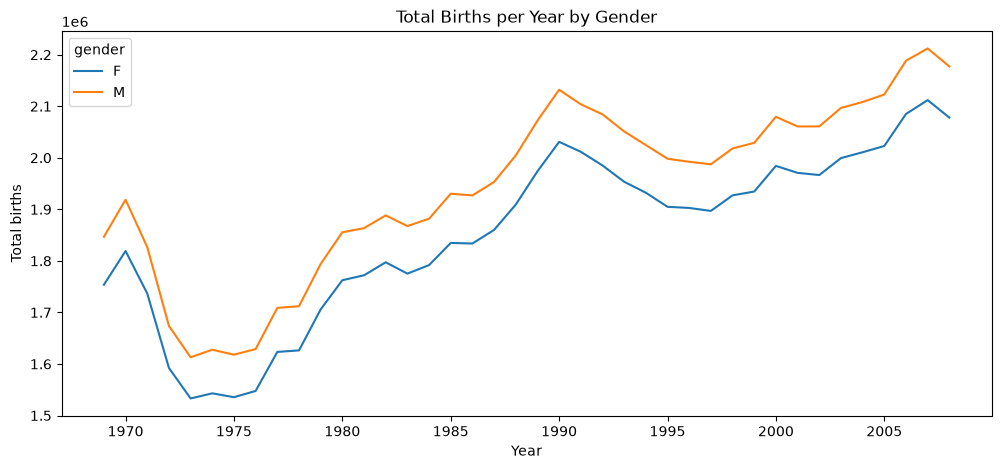

In [8]:
# (c) Total births per year by gender
yearly = births.pivot_table("births", index="year", columns="gender", aggfunc="sum")
ax = yearly.plot(figsize=(12, 5), title="Total Births per Year by Gender")
ax.set_xlabel("Year")
ax.set_ylabel("Total births")
plt.show()

## Task 3: Data Cleaning with Sigma-Clipping

In [9]:
# (a) Robust mean (median) and robust sigma from the quartiles
q1, q2, q3 = np.percentile(births["births"], [25, 50, 75])
mu = q2
sigma = 0.74 * (q3 - q1)
print("Q1:", q1, "| Median (mu):", mu, "| Q3:", q3, "| Robust sigma:", sigma)

Q1: 4358.0 | Median (mu): 4814.0 | Q3: 5289.5 | Robust sigma: 689.31


In [10]:
# (b) Keep only rows within 5 sigma of mu
births_clean = births.query("(@mu - 5 * @sigma) <= births <= (@mu + 5 * @sigma)").copy()
print("Rows before:", len(births))
print("Rows after :", len(births_clean))
print("Rows removed:", len(births) - len(births_clean))

Rows before: 15547
Rows after : 14610
Rows removed: 937


In [11]:
# (c) Now the day column can be converted to integers
births_clean["day"] = births_clean["day"].astype(int)
print(births_clean.dtypes)
births_clean.head()

year       int64
month      int64
day        int64
gender    object
births     int64
decade     int64
dtype: object


,year,month,day,gender,births,decade
0,1969,1,1,F,4046,1960
1,1969,1,1,M,4440,1960
2,1969,1,2,F,4454,1960
3,1969,1,2,M,4548,1960
4,1969,1,3,F,4548,1960


## Task 4: Datetime Index and Weekday Analysis

In [12]:
# (a) Combine year, month and day into a DatetimeIndex
births_clean["date"] = pd.to_datetime(10000 * births_clean.year + 100 * births_clean.month + births_clean.day, format="%Y%m%d")
births_clean = births_clean.set_index("date")
births_clean["dayofweek"] = births_clean.index.dayofweek
births_clean.head()

,year,month,day,gender,births,decade,dayofweek
date,,,,,,,
1969-01-01,1969,1,1,F,4046,1960,2
1969-01-01,1969,1,1,M,4440,1960,2
1969-01-02,1969,1,2,F,4454,1960,3
1969-01-02,1969,1,2,M,4548,1960,3
1969-01-03,1969,1,3,F,4548,1960,4


In [13]:
# (b) Mean births by day of week and decade
weekday_table = births_clean.pivot_table("births", index="dayofweek", columns="decade", aggfunc="mean")
weekday_table.round(1)

decade,1960,1970,1980
dayofweek,,,
0,5063.8,4689.1,5276.9
1,5286.1,4885.3,5503.8
2,5074.6,4750.4,5367.6
3,4978.3,4696.9,5333.5
4,5107.9,4782.1,5393.1
5,4651.1,4207.8,4483.9
6,4342.3,3979.3,4308.1


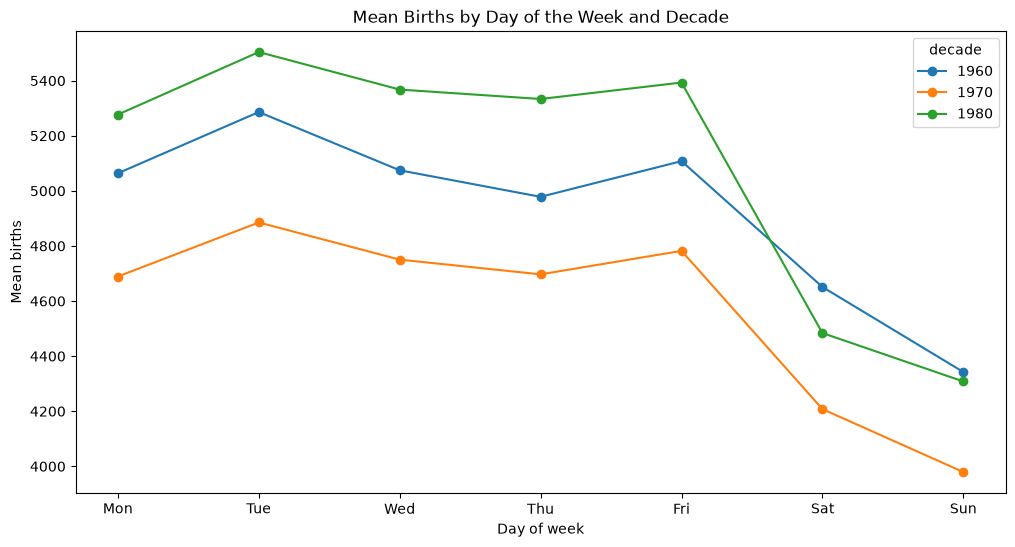

In [14]:
ax = weekday_table.plot(figsize=(12, 6), marker="o", title="Mean Births by Day of the Week and Decade")
ax.set_xticks(range(7))
ax.set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xlabel("Day of week")
ax.set_ylabel("Mean births")
plt.show()

## Task 5: Births by Day of the Year

In [15]:
# Mean births for each (month, day) pair
births_by_date = births_clean.pivot_table("births", index=["month", "day"], aggfunc="mean")["births"]
births_by_date.head(10)

month  day
1      1      4009.225
       2      4247.400
       3      4500.900
       4      4571.350
       5      4603.625
       6      4668.150
       7      4706.925
       8      4629.650
       9      4537.775
       10     4591.700
Name: births, dtype: float64

In [16]:
# (a) Attach a dummy LEAP year (2012) so that February 29 is a valid date
births_by_date.index = pd.to_datetime(10000 * 2012 + 100 * births_by_date.index.get_level_values(0) + births_by_date.index.get_level_values(1), format="%Y%m%d")
births_by_date = births_by_date.sort_index()
births_by_date.head()

2012-01-01    4009.225
2012-01-02    4247.400
2012-01-03    4500.900
2012-01-04    4571.350
2012-01-05    4603.625
Name: births, dtype: float64

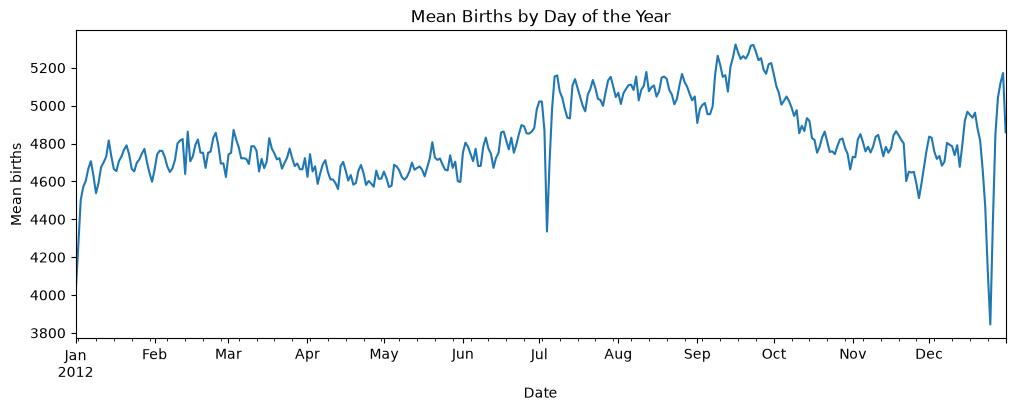

In [17]:
# (b) Plot mean births by day of the year
ax = births_by_date.plot(figsize=(12, 4), title="Mean Births by Day of the Year")
ax.set_xlabel("Date")
ax.set_ylabel("Mean births")
plt.show()

## Task 6: Pivot Table versus GroupBy

In [18]:
# (a) Reproduce the Task 2 table using groupby + unstack
gb_table = births.groupby(["decade", "gender"])["births"].sum().unstack()
print("Identical to pivot_table result:", gb_table.equals(decade_totals))
gb_table

Identical to pivot_table result: True


gender,F,M
decade,,
1960,1753634,1846572
1970,16263075,17121550
1980,18310351,19243452
1990,19479454,20420553
2000,18229309,19106428


In [19]:
# (b) Time both approaches (run this cell in Jupyter — %timeit is a notebook magic)
%timeit births.pivot_table("births", index="decade", columns="gender", aggfunc="sum")
%timeit births.groupby(["decade", "gender"])["births"].sum().unstack()

4.07 ms ± 156 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


1.75 ms ± 61 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


## Bonus: Holiday Dips

In [20]:
# Five dates with the lowest mean births
births_by_date.nsmallest(5)

2012-12-25    3844.450
2012-01-01    4009.225
2012-12-24    4126.250
2012-01-02    4247.400
2012-07-04    4335.325
Name: births, dtype: float64

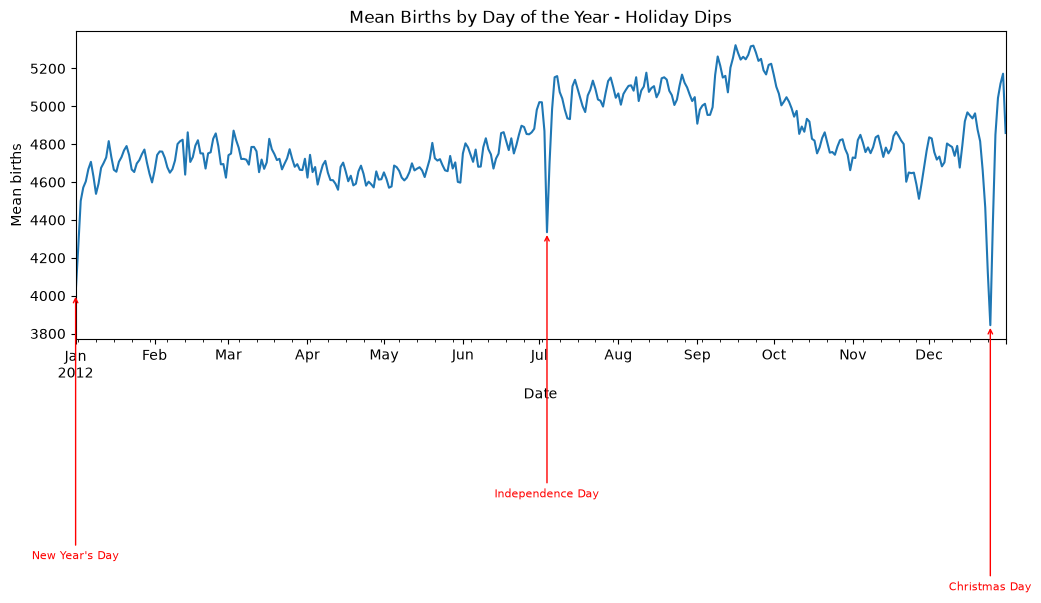

In [21]:
# Annotate at least three holiday dips on the plot
fig, ax = plt.subplots(figsize=(12, 4))
births_by_date.plot(ax=ax, title="Mean Births by Day of the Year - Holiday Dips")
ax.set_xlabel("Date")
ax.set_ylabel("Mean births")
for d, label in [(pd.Timestamp("2012-01-01"), "New Year's Day"), (pd.Timestamp("2012-07-04"), "Independence Day"), (pd.Timestamp("2012-12-25"), "Christmas Day")]:
    y = births_by_date.loc[d]
    ax.annotate(label, xy=(d, y), xytext=(d, y - 1400), arrowprops=dict(arrowstyle="->", color="red"), color="red", ha="center", fontsize=8)
plt.show()